# E03 — Earthing grid of a high-voltage substation in two-layer soil

This case study takes the mesh earthing grid of an outdoor high-voltage
substation through the touch-voltage verification of EN 50522:2022, in
two-layer soil. It is written for grounding engineers who know the
standard and IEEE Std 80 and want to see how `groundfield` answers the
design questions, which engine to trust for which quantity, and how far
the numbers carry.

**Questions this example answers**

1. What is the earthing impedance $Z_E$ of the grid, and how much does
   the two-layer soil change it against a homogeneous estimate?
2. Which earth potential rise $U_E$, and which touch and step voltages,
   does an earth-fault current of 2 kA cause?
3. Does the design meet the permissible touch voltage for a fault
   cleared in 0.5 s, and what would make it pass?
4. Is the discretisation fine enough, and how do `image_2layer`, `mom`
   and the closed-form estimates compare?
5. How do the layer contrast and the depth of the interface change the
   results?

The tutorials [T02](../tutorials/T02_layered_soil.ipynb) (layered soil),
[T08](../tutorials/T08_touch_and_step_assessment.ipynb) (touch and step
voltages) and
[T09](../tutorials/T09_choosing_an_engine_and_convergence.ipynb)
(engines and convergence) introduce the functions used here. This
example applies them to one installation.

Runtime: about 70 s.

## 1. The installation and the soil

| Part | Model | Note |
|---|---|---|
| Grid | 60 m × 40 m, 12 × 8 meshes of 5 m | 22 conductors, 1060 m |
| Burial depth | 0.8 m | |
| Conductor | round copper, radius 6 mm | 113 mm² |
| Rods | 4 × 3 m at the corners, radius 8 mm | from 0.8 m to 3.8 m depth |
| Earth-fault current | $I_E$ = 2 kA at 50 Hz | flows from the grid into the soil |
| Fault duration | $t_f$ = 0.5 s | clearing time of the protection |

The earth-fault current $I_E$ is the part of the fault current that
leaves the grid through the soil. The rest returns to the source over
the earth wires of the overhead lines and the screens of the cables. In
a real study $I_E$ follows from the network's fault currents and these
reduction factors; here it is an assumption.

**The soil.** A two-layer soil has an upper layer of resistivity
$\rho_1$ and thickness $h_1$ over a half-space of resistivity $\rho_2$.
The interface reflects part of the current field with the factor

$$
K = \frac{\rho_2 - \rho_1}{\rho_2 + \rho_1}, \qquad -1 < K < 1 .
$$

We take two soils with the same two resistivities in reverse order:

| Soil | $\rho_1$ | $h_1$ | $\rho_2$ | $K$ | For example |
|---|---|---|---|---|---|
| A | 300 Ω·m | 2.5 m | 50 Ω·m | −0.71 | dry sand over groundwater |
| B | 50 Ω·m | 2.5 m | 300 Ω·m | +0.71 | loam over dry gravel or rock |

The grid lies in the upper layer in both soils; the rods reach 1.3 m
into the lower one.

### Modelling choices

- **The grid** is one `grid_mesh` electrode: its 22 conductors are
  straight wires, connected at every crossing.
- **The rods** are separate `rod` electrodes, bonded to the grid by
  ideal conductors (`create_conductor` without a cross-section). An
  ideal bond merges the electrodes into one cluster at one potential;
  the route of the bond does not matter.
- **One potential for the whole grid.** `groundfield` treats an
  electrode as an equipotential body: the resistance and inductance of
  the copper are neglected. That is the usual assumption of grid design
  (IEEE Std 80 makes it too) for a compact copper grid at 50 Hz.
- **The source** is a current $I_E$ into the grid that returns at remote
  earth. The problem is linear, so every voltage scales with $I_E$.
- **The touched parts.** All metal structures in the yard (steel
  supports, equipment frames) are bonded to the grid, and people may
  stand anywhere inside the yard. The yard fence runs on the line of the
  outer conductor and is bonded to the grid; people outside the fence
  stand 1 m from it.

### The engines

Two engines solve thin wires in two-layer soil with the Tagg/Sunde image
series:

- `image_2layer` (what the default `image` runs for two-layer soil)
  gives every straight wire one uniform leakage current and integrates
  its potential exactly (line kernel). Its impedances are within about
  1–2 % of `mom`, but near grids its surface potential is only
  impedance-grade: it cannot let the current crowd towards the ends of
  each wire, and it warns with `UniformCurrentFieldWarning`.
- `mom` gives every segment its own current (piecewise constant, point
  matching at the segment midpoints, point kernel), so the current
  concentrates at the edges and corners of the grid as it does in
  reality. Its touch and step voltages are field-grade.

We therefore compute everything with `mom` and use `image_2layer` and
`mom_sommerfeld` (the same discretisation, with the layered Green's
function as a Sommerfeld integral) as cross-checks in section 8. `fem`
is not used: its three-dimensional model needed 75–140 s and 4.3 GB for
a station with 28 m of wire ([`fem` engine
page](../explanation/engines/fem.md)), and this grid has 1072 m.

## 2. Build the model

One function builds the earthing system, so that the design variants of
section 7 differ only in their arguments. The segment length `DS` of 1 m
is justified in section 3.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf
from groundfield.references import dwight1936, ieee80

print("groundfield", gf.__version__)
T_START = time.perf_counter()

I_E = 2000.0  # A, earth-fault current from the grid into the soil
T_F = 0.5  # s, fault duration
SIZE = (60.0, 40.0)  # m
MESHES = (12, 8)  # 5 m x 5 m meshes
DEPTH = 0.8  # m, burial depth of the grid
ROD_LENGTH = 3.0  # m
DS = 1.0  # m, segment length of mom (section 3)

SOILS = {
    "A": gf.TwoLayerSoil(rho_1=300.0, rho_2=50.0, h_1=2.5),  # resistive over conductive
    "B": gf.TwoLayerSoil(rho_1=50.0, rho_2=300.0, h_1=2.5),  # conductive over resistive
}
for name, soil in SOILS.items():
    K = (soil.rho_2 - soil.rho_1) / (soil.rho_2 + soil.rho_1)
    print(f"soil {name}: {soil.rho_1:.0f} over {soil.rho_2:.0f} Ohm m, h_1 = {soil.h_1} m, K = {K:+.3f}")

groundfield 2026.11.0
soil A: 300 over 50 Ohm m, h_1 = 2.5 m, K = -0.714
soil B: 50 over 300 Ohm m, h_1 = 2.5 m, K = +0.714


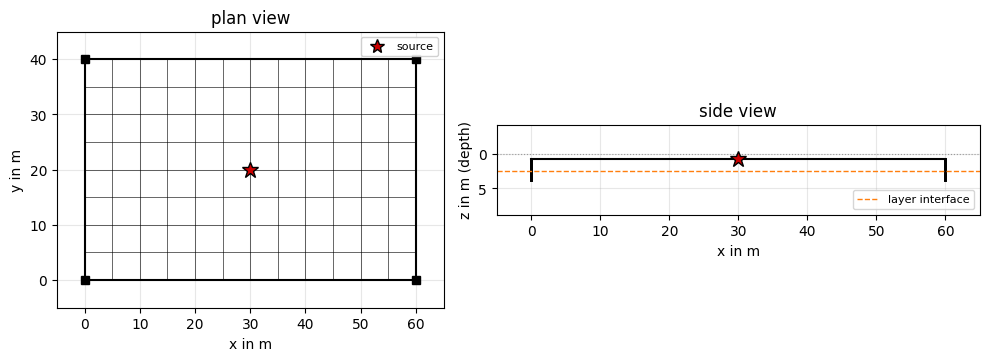

In [2]:
def substation(soil, *, meshes=MESHES, rods="corners", rod_length=ROD_LENGTH, grading=False):
    """The substation earth, fed with I_E: grid, bonded rods, optional grading conductor."""
    world = gf.create_world(soil=soil)
    lx, ly = SIZE
    gf.create_electrode(
        world, "grid_mesh", name="grid", corner=(0.0, 0.0, DEPTH), size=SIZE,
        n_x=meshes[0], n_y=meshes[1], wire_radius=0.006,
    )
    if rods == "corners":
        heads = [(0.0, 0.0), (lx, 0.0), (lx, ly), (0.0, ly)]
    else:  # "perimeter": every 10 m along the outer conductor
        heads = [(x, y) for x in np.arange(0.0, lx + 1.0, 10.0) for y in (0.0, ly)]
        heads += [(x, y) for y in np.arange(10.0, ly, 10.0) for x in (0.0, lx)]
    for k, (x, y) in enumerate(heads):
        gf.create_electrode(
            world, "rod", name=f"rod_{k}", position=(x, y, DEPTH),
            length=rod_length, wire_radius=0.008,
        )
        gf.create_conductor(world, name=f"bond_{k}", start="grid", end=f"rod_{k}")  # ideal
    if grading:  # a closed conductor 1 m outside the grid, 0.5 m deep, bonded
        ring = [(-1.0, -1.0, 0.5), (lx + 1, -1.0, 0.5), (lx + 1, ly + 1, 0.5), (-1.0, ly + 1, 0.5)]
        gf.create_electrode(world, "polyline", name="grading", vertices=ring, wire_radius=0.005)
        gf.create_conductor(world, name="bond_grading", start="grid", end="grading")
    gf.create_source(world, attached_to="grid", magnitude=I_E)
    return world


worlds = {name: substation(soil) for name, soil in SOILS.items()}

fig, (ax_plan, ax_side) = plt.subplots(1, 2, figsize=(10.0, 3.6), width_ratios=[1.0, 1.25])
gf.plot_world(worlds["A"], ax=ax_plan, show_conductors=False, title="plan view")
gf.plot_world(worlds["A"], plane="xz", ax=ax_side, show_conductors=False, title="side view")
ax_side.axhline(SOILS["A"].h_1, color="C1", ls="--", lw=1.0, label="layer interface")
ax_side.legend(fontsize=8, loc="lower right")
fig.tight_layout()

## 3. Is the discretisation fine enough?

Before reading any number we check that it does not depend on the
segment length. `gf.convergence_study` solves the same world with a
ladder of segment lengths; a `response` function adds the touch
voltages to the impedance. The helper `touch` returns the three touch
voltages this example assesses:

- **outside**: the largest value with the feet 1 m outside the grid,
  where people outside the fence stand (`touch_voltage_envelope`);
- **mesh**: the largest value at the centres of the meshes, the *mesh
  voltage* of IEEE Std 80 (`interior="meshes"`);
- **yard**: the largest value anywhere inside the fence. It lies either
  at a mesh centre or on the fence line above the outer conductor, so
  `touch` also samples that line every metre. Section 5 confirms this
  against a dense map.

`touch_voltage_envelope` places the feet on rays from the centre of the
grid. Its default of 24 rays misses the rounded corners of a
60 m × 40 m rectangle, where the touch voltage is largest (section 5
shows by how much), so we use 360 rays.

`mom` needs segments shorter than about 2 m here. Its point form of the
layered Green's function averages over ±0.387 segment lengths in depth;
for longer segments that range would reach above the soil surface, and
the engine refuses the world with `BackendCapabilityError`. The ladder
therefore starts at 2 m.

In [3]:
N_ANGLES = 360  # rays of the envelope, 1 degree apart
ALONG_X = np.arange(0.0, SIZE[0] + 1e-9, 1.0)
ALONG_Y = np.arange(0.0, SIZE[1] + 1e-9, 1.0)
FENCE_LINE = np.array(  # on the surface above the outer conductor, 1 m apart
    [(x, y, 0.0) for x in ALONG_X for y in (0.0, SIZE[1])]
    + [(x, y, 0.0) for y in ALONG_Y for x in (0.0, SIZE[0])]
)


def touch(result, world):
    """Largest |U_T| in V: outside the fence, at the mesh centres, anywhere in the yard."""
    _, u_t = gf.touch_voltage_envelope(
        result, world, electrode="grid", interior="meshes", n_angles=N_ANGLES
    )
    u_t = np.abs(u_t)
    u_line = np.abs(result.electrode_potentials["grid"][0] - result.potential(FENCE_LINE))
    mesh = u_t[N_ANGLES:].max()
    return {"outside": u_t[:N_ANGLES].max(), "mesh": mesh, "yard": max(mesh, u_line.max())}


def response(result, world, k):
    return {"Z_E": result.input_impedance()[k].real, **touch(result, world)}


mom = gf.create_engine(backend="mom", segment_length=DS)
ladder = [2.0, 1.0, 0.5, 0.25]
convergence = {
    name: gf.convergence_study(world, mom, segment_lengths=ladder, response=response)
    for name, world in worlds.items()
}
for name, df in convergence.items():
    finest = df.iloc[-1]
    print(f"soil {name}: deviation from the finest step (0.25 m)")
    print("  ds in m  segments  Z_E in Ohm    Z_E     U_T outside  U_T yard")
    for _, row in df.iterrows():
        dev = {q: row[q] / finest[q] - 1.0 for q in ("Z_E", "outside", "yard")}
        print(
            f"   {row['segment_length_m']:5.2f}   {row['n_segments']:6.0f}   {row['Z_E']:8.5f}"
            f"   {dev['Z_E']:+7.2%}    {dev['outside']:+7.2%}    {dev['yard']:+7.2%}"
        )

soil A: deviation from the finest step (0.25 m)
  ds in m  segments  Z_E in Ohm    Z_E     U_T outside  U_T yard
    2.00      644    0.78144    -0.42%     +0.28%     -1.31%
    1.00     1076    0.78326    -0.19%     -0.12%     -0.52%
    0.50     2148    0.78452    -0.03%     -0.00%     -0.07%
    0.25     4292    0.78473    +0.00%     +0.00%     +0.00%
soil B: deviation from the finest step (0.25 m)
  ds in m  segments  Z_E in Ohm    Z_E     U_T outside  U_T yard
    2.00      644    1.74870    -0.02%     +1.13%     +3.86%
    1.00     1076    1.74872    -0.02%     +0.12%     +0.13%
    0.50     2148    1.74892    -0.01%     -0.03%     -0.15%
    0.25     4292    1.74903    +0.00%     +0.00%     +0.00%


In [4]:
for df in convergence.values():
    at_ds = df[df["segment_length_m"] == DS].iloc[0]
    finest = df.iloc[-1]
    for q in ("Z_E", "outside", "yard"):
        assert abs(at_ds[q] / finest[q] - 1.0) < 0.01  # 1 m is within 1 % of 0.25 m
    assert np.all(np.diff(df["Z_E"]) > 0)  # the impedance rises monotonically

With 1 m segments the impedance is within 0.2 % of the 0.25 m value and
the touch voltages within 0.6 %. The impedance rises steadily as the
segments shrink: the point kernel of `mom` converges to a value slightly
below the exact one (T09 shows it for a rod). The effect on the design
is far smaller than the uncertainty of any soil model. We keep 1 m.

## 4. Grid impedance and earth potential rise

In homogeneous soil the impedance is proportional to the resistivity,
$Z_E = \rho\, z_1$. One solve gives the impedance per Ω·m, $z_1$, and
with it both homogeneous limits: $\rho_1 z_1$ for a very thick and
$\rho_2 z_1$ for a very thin upper layer. The two-layer impedance must
lie between them. The *apparent resistivity* $\rho_a = Z_E / z_1$ is
the homogeneous resistivity that would give the same impedance.

Sverak's formula of IEEE Std 80 (2000, Eq. 57) is the engineering
estimate for grids in homogeneous soil, with the total conductor length
$L_T$ (grid and rods), the area $A$ and the depth $h$:

$$
R_g = \rho\left[\frac{1}{L_T} + \frac{1}{\sqrt{20A}}\left(1 +
\frac{1}{1 + h\sqrt{20/A}}\right)\right].
$$

With $Z_E$ the earth potential rise is $U_E = Z_E I_E$.

In [5]:
results = {name: mom.solve(world) for name, world in worlds.items()}
z_e = {name: res.input_impedance()[0].real for name, res in results.items()}
u_e = {name: abs(res.electrode_potentials["grid"][0]) for name, res in results.items()}

hom_world = substation(gf.HomogeneousSoil(rho=100.0))
homogeneous = mom.solve(hom_world)
z_1 = homogeneous.input_impedance()[0].real / 100.0  # Ohm per Ohm m
L_T = 13 * 40.0 + 9 * 60.0 + 4 * ROD_LENGTH  # m, grid conductors and rods
sverak_1 = ieee80.grid_resistance_sverak(1.0, total_conductor_length=L_T, area=2400.0, depth=DEPTH)

print(
    f"homogeneous soil: z_1 = {z_1 * 1e3:.4f} mOhm per Ohm m (mom), "
    f"Sverak {sverak_1 * 1e3:.4f} ({sverak_1 / z_1 - 1:+.1%})"
)
print()
print("soil  Z_E (mom)    U_E at 2 kA  rho_2 limit  rho_1 limit  rho_a")
for name, soil in SOILS.items():
    print(
        f"  {name}   {z_e[name]:.4f} Ohm   {u_e[name]:6.0f} V    {soil.rho_2 * z_1:.4f} Ohm"
        f"   {soil.rho_1 * z_1:.4f} Ohm   {z_e[name] / z_1:5.1f} Ohm m"
    )

homogeneous soil: z_1 = 8.9525 mOhm per Ohm m (mom), Sverak 9.7509 (+8.9%)

soil  Z_E (mom)    U_E at 2 kA  rho_2 limit  rho_1 limit  rho_a
  A   0.7833 Ohm     1567 V    0.4476 Ohm   2.6858 Ohm    87.5 Ohm m
  B   1.7487 Ohm     3497 V    2.6858 Ohm   0.4476 Ohm   195.3 Ohm m


In [6]:
for name, soil in SOILS.items():
    low, high = sorted((soil.rho_1 * z_1, soil.rho_2 * z_1))
    assert low < z_e[name] < high  # between the homogeneous limits
    assert abs(u_e[name] / (z_e[name] * I_E) - 1.0) < 1e-9  # U_E = Z_E I_E
assert 0.0 < sverak_1 / z_1 - 1.0 < 0.15  # IEEE 80 is an empirical formula, a little high
assert abs(z_e["A"] - 0.78326) < 5e-4 and abs(z_e["B"] - 1.74872) < 5e-4

**Plausibility.** Sverak's formula lies +8.9 % above `mom` in
homogeneous soil, its usual accuracy for grids (T08 finds +11.8 % for a
20 m grid). It has no two-layer form, but the two-layer results lie
between the homogeneous limits, as they must.

**What the soil does.** The two soils contain the same resistivities,
yet their impedances differ by a factor of 2.2. A 60 m × 40 m grid
drives its current tens of metres deep, so it sees mainly the lower
layer: the apparent resistivity is 88 Ω·m in soil A, near the
50 Ω·m of the bottom, and 195 Ω·m in soil B, nearer the 300 Ω·m of
the bottom than the 50 Ω·m around the grid. A sounding that stops a few
metres deep would misjudge this grid badly.

**The rods.** The four corner rods carry only a few per cent of the
current:

In [7]:
rod_share = {}
for name, res in results.items():
    rod_share[name] = sum(abs(res.electrode_currents[f"rod_{k}"][0]) for k in range(4)) / I_E
    print(f"soil {name}: the four rods leak {rod_share[name]:.1%} of I_E")
for rho in (50.0, 300.0):
    print(f"one 3 m rod alone in {rho:.0f} Ohm m (Dwight): {dwight1936.rod(rho, ROD_LENGTH, 0.008):.1f} Ohm")
assert all(share < 0.1 for share in rod_share.values())

soil A: the four rods leak 6.8% of I_E
soil B: the four rods leak 3.7% of I_E
one 3 m rod alone in 50 Ohm m (Dwight): 16.7 Ohm
one 3 m rod alone in 300 Ohm m (Dwight): 100.5 Ohm


A single 3 m rod alone would have 17 to 100 Ω, depending on the layer it
stands in (Dwight's closed form for homogeneous soil): ten to a hundred
times the impedance of the grid. And the corner rods stand in the
potential well of the grid. Rods of 3 m therefore change $Z_E$ little;
section 7 shows what longer rods do.

**EN 50522 first.** EN 50522:2022, 5.4.2, accepts the design without a
touch-voltage calculation if $U_E \le 2\,U_{Tp}$ (criterion C2), or if
$U_E \le 4\,U_{Tp}$ and the measures M of Annex E, Table E.1, are taken
(C3). Otherwise (C4) the touch voltages must be shown to stay below the
permissible value, by calculation or measurement. `groundfield`
provides the permissible touch voltage $U_{Tp}(t_f)$ of Table B.4
(`gf.permissible_touch_voltage_en50522`):

In [8]:
u_tp = gf.permissible_touch_voltage_en50522(T_F)
print(f"U_Tp({T_F} s) = {u_tp:.0f} V: 2 U_Tp = {2 * u_tp:.0f} V, 4 U_Tp = {4 * u_tp:.0f} V")
for name in SOILS:
    print(f"soil {name}: U_E = {u_e[name]:.0f} V = {u_e[name] / u_tp:.1f} U_Tp -> criterion C4")

U_Tp(0.5 s) = 225 V: 2 U_Tp = 450 V, 4 U_Tp = 900 V
soil A: U_E = 1567 V = 7.0 U_Tp -> criterion C4
soil B: U_E = 3497 V = 15.5 U_Tp -> criterion C4


In [9]:
assert u_tp == 225.0  # EN 50522:2022, Table B.4, 0.5 s
assert all(u > 4 * u_tp for u in u_e.values())

Both soils lead to criterion C4: we compute the touch voltages.

## 5. Touch voltages on the surface

The touch voltage is the difference between the potential of the touched
part, here the earth potential rise $U_E$ of the grid, and the potential
of the soil surface under the feet, 1 m away:

$$
U_T = U_E - \varphi(\mathbf r_\text{feet}).
$$

This is the prospective (open-circuit) value: no body current flows. We
evaluate the surface potential $\varphi$ on a grid of points 0.5 m apart
that covers the yard and 5 m around it, 141 × 101 points. The grid, the
rods and the feeding point are symmetric about both centre lines, so one
quarter (3621 points) is computed and mirrored. Inside the yard every
point is a possible standing position next to a bonded structure, so the
map *is* the touch voltage there. Outside, $U_E - \varphi$ is a touch
voltage only where a bonded part stands within 1 m: along the fence.

In [10]:
x_q = np.arange(-5.0, SIZE[0] / 2 + 1e-9, 0.5)  # the lower left quarter
y_q = np.arange(-5.0, SIZE[1] / 2 + 1e-9, 0.5)
X_q, Y_q = np.meshgrid(x_q, y_q)
quarter = np.column_stack([X_q.ravel(), Y_q.ravel(), np.zeros(X_q.size)])
x = np.concatenate([x_q, SIZE[0] - x_q[-2::-1]])  # -5 ... 65 m
y = np.concatenate([y_q, SIZE[1] - y_q[-2::-1]])  # -5 ... 45 m
X, Y = np.meshgrid(x, y)
in_yard = (X >= 0.0) & (X <= SIZE[0]) & (Y >= 0.0) & (Y <= SIZE[1])


def mirror(q):
    """The full map from its lower left quarter."""
    half = np.hstack([q, q[:, -2::-1]])
    return np.vstack([half, half[-2::-1, :]])


u_map = {}
for name, res in results.items():
    phi = res.potential(quarter).reshape(X_q.shape)
    u_map[name] = mirror(np.abs(res.electrode_potentials["grid"][0] - phi))

limits = {name: touch(res, worlds[name]) for name, res in results.items()}
for name, u in u_map.items():
    k = np.argmax(np.where(in_yard, u, -np.inf))
    print(
        f"soil {name}: in the yard {u[in_yard].min():.0f} ... {u.flat[k]:.0f} V, the largest at "
        f"({X.flat[k]:.1f}, {Y.flat[k]:.1f}) m; above U_Tp on {np.sum(u[in_yard] > u_tp)} "
        f"of {in_yard.sum()} points; 1 m outside the grid up to {limits[name]['outside']:.0f} V"
    )

soil A: in the yard 217 ... 552 V, the largest at (2.5, 2.5) m; above U_Tp on 9786 of 9801 points; 1 m outside the grid up to 710 V
soil B: in the yard 14 ... 301 V, the largest at (0.0, 0.0) m; above U_Tp on 28 of 9801 points; 1 m outside the grid up to 486 V


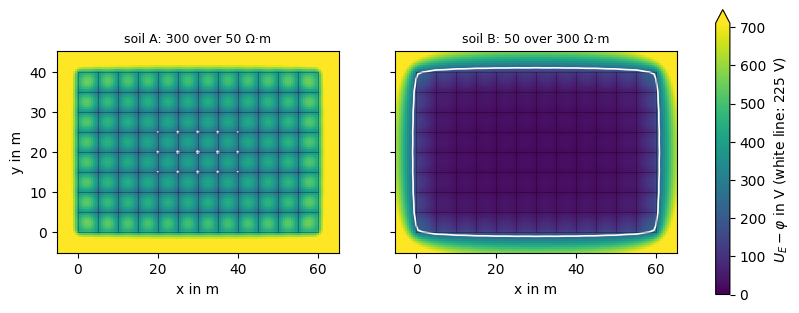

In [11]:
for name, u in u_map.items():
    assert abs(u[in_yard].max() / limits[name]["yard"] - 1.0) < 1e-6  # touch() finds the maximum

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.7), sharey=True)
vmax = max(lim["outside"] for lim in limits.values())  # brighter colours: beyond the fence
for ax, (name, u) in zip(axes, u_map.items()):
    image_plot = ax.pcolormesh(x, y, u, shading="nearest", cmap="viridis", vmin=0.0, vmax=vmax)
    ax.contour(x, y, u, levels=[u_tp], colors="white", linewidths=1.2)
    for xk in np.linspace(0.0, SIZE[0], MESHES[0] + 1):
        ax.plot([xk, xk], [0.0, SIZE[1]], color="k", lw=0.4, alpha=0.5)
    for yk in np.linspace(0.0, SIZE[1], MESHES[1] + 1):
        ax.plot([0.0, SIZE[0]], [yk, yk], color="k", lw=0.4, alpha=0.5)
    soil = SOILS[name]
    ax.set_title(f"soil {name}: {soil.rho_1:.0f} over {soil.rho_2:.0f} Ω·m", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xlabel("x in m")
axes[0].set_ylabel("y in m")
fig.colorbar(image_plot, ax=axes, extend="max", label=r"$U_E - \varphi$ in V (white line: 225 V)")

The colour scale ends at the largest touch voltage outside the fence.
Farther out, $U_E - \varphi$ keeps growing towards $U_E$, but no bonded
part stands there. The maps show the two faces of a two-layer soil:

- In **soil A** (resistive over conductive) the surface potential sags
  in every mesh. The touch voltage in the yard lies between 217 V and
  552 V, highest in the corner meshes; it is above $U_{Tp}$ = 225 V
  almost everywhere (9786 of 9801 points).
- In **soil B** (conductive over resistive) the conductive top layer
  spreads the current sideways and flattens the surface potential. In
  the yard only the corners exceed $U_{Tp}$, with 301 V right above
  the corner conductor, although $U_E$ is more than twice as high as in
  soil A.

In both soils the largest touch voltage stands outside the corners,
where the potential falls fastest. That is where `mom` matters: the
current per metre is largest at the ends of the outer conductors.

Two checks of the values outside the fence. The fence post at a corner,
touched from outside along the diagonal, is the standing position of
the envelope's maximum; and the default of 24 rays misses it:

In [12]:
for name, res in results.items():
    _, u_post = gf.touch_voltage_at_part(
        res, worlds[name], position=(0.0, 0.0), bonded_to="grid", directions=[(-1.0, -1.0)]
    )
    _, u_24 = gf.touch_voltage_envelope(res, worlds[name], electrode="grid")  # 24 rays
    print(
        f"soil {name}: corner post {abs(u_post[0]):.1f} V; envelope with 360 rays "
        f"{limits[name]['outside']:.1f} V, with the default 24 rays {np.abs(u_24).max():.1f} V "
        f"({np.abs(u_24).max() / limits[name]['outside'] - 1:+.0%})"
    )
    assert abs(abs(u_post[0]) / limits[name]["outside"] - 1.0) < 1e-3
    assert np.abs(u_24).max() < 0.95 * limits[name]["outside"]  # 24 rays miss the corner

soil A: corner post 710.4 V; envelope with 360 rays 710.4 V, with the default 24 rays 627.6 V (-12%)
soil B: corner post 486.4 V; envelope with 360 rays 486.4 V, with the default 24 rays 351.8 V (-28%)


With 24 rays the envelope reads 12 % low in soil A and 28 % low in
soil B, on the unsafe side. For a rectangular grid, raise `n_angles`
until the maximum stops changing, or put touch points at the corners
with `touch_voltage_at_part`. (The default happens to hit the corners of
a *square* grid, whose diagonals lie at multiples of 15°.)

## 6. Step voltages

A person walking near the grid bridges the step voltage between two
points 1 m apart,

$$
U_S = \varphi(\mathbf r) - \varphi(\mathbf r + 1\,\mathrm m\;\hat{\mathbf e}).
$$

It is largest where the surface potential falls fastest, at the
corners. We evaluate it along two lines out of the grid, the diagonal
through a corner and the normal through the middle of a long side, from
inside the outer mesh to 12 m outside. The step points outwards; the
plot shows its magnitude.

soil A, diagonal through the corner: largest U_S = 214 V, first foot at -0.1 m
soil A, normal through the middle of the long side: largest U_S = 197 V, first foot at +0.2 m
soil B, diagonal through the corner: largest U_S = 185 V, first foot at +0.0 m
soil B, normal through the middle of the long side: largest U_S = 104 V, first foot at +0.4 m


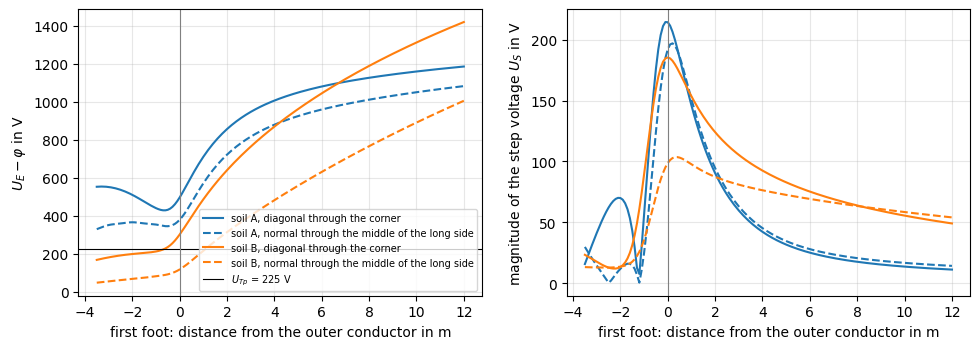

In [13]:
s = np.arange(-3.5, 12.0 + 1e-9, 0.1)  # m from the outer conductor, positive outside
lines = {
    "diagonal through the corner": ((0.0, 0.0), np.array([-1.0, -1.0]) / np.sqrt(2.0)),
    "normal through the middle of the long side": ((30.0, 0.0), np.array([0.0, -1.0])),
}
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.6), sharex=True)
u_s_max = {}
for name, res in results.items():
    for (label, (origin, e)), ls in zip(lines.items(), ("-", "--")):
        p = np.column_stack([origin[0] + s * e[0], origin[1] + s * e[1], np.zeros_like(s)])
        phi = res.potential(p).real
        u_s = np.abs(phi - res.potential(p + np.append(e, 0.0)).real)
        u_s_max[name, label] = (u_s.max(), s[np.argmax(u_s)])
        color = "C0" if name == "A" else "C1"
        axes[0].plot(s, u_e[name] - phi, ls, color=color, label=f"soil {name}, {label}")
        axes[1].plot(s, u_s, ls, color=color)
axes[0].axhline(u_tp, color="k", lw=0.8, label="$U_{Tp}$ = 225 V")
axes[0].set_ylabel(r"$U_E - \varphi$ in V")
axes[1].set_ylabel("magnitude of the step voltage $U_S$ in V")
for ax in axes:
    ax.axvline(0.0, color="grey", lw=0.8)
    ax.set_xlabel("first foot: distance from the outer conductor in m")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
fig.tight_layout()

for (name, label), (u, at) in u_s_max.items():
    print(f"soil {name}, {label}: largest U_S = {u:.0f} V, first foot at {round(at, 1) + 0.0:+.1f} m")

In [14]:
corner = (-1.0 / np.sqrt(2.0), -1.0 / np.sqrt(2.0), 0.0)  # 1 m outside the corner
step_mom = {}
for name, res in results.items():
    step_mom[name] = abs(
        gf.step_voltage(res, position=corner, direction=(-1.0, -1.0, 0.0), world=worlds[name])
    )
    print(f"soil {name}: gf.step_voltage from 1 m to 2 m outside the corner: {step_mom[name]:.1f} V")
    largest = u_s_max[name, "diagonal through the corner"][0]
    assert step_mom[name] <= largest + 1e-9 and largest < limits[name]["outside"]
    assert u_e[name] < 20 * u_tp  # EN 50522, 5.4.2, note 1

soil A: gf.step_voltage from 1 m to 2 m outside the corner: 145.9 V
soil B: gf.step_voltage from 1 m to 2 m outside the corner: 153.4 V


The largest step voltages, 214 V in soil A and 185 V in soil B,
begin at the corner and stay below the touch voltages. EN 50522:2022
rarely asks for them, and Annex A.3 gives the reason: the permissible
step voltages are much higher than the permissible touch voltages,
because the current from foot to foot passes the heart with a
heart-current factor of only 0.04. The standard asks for the step voltages at the
boundary of an installation only for high earth potential rises, and
names $U_E > 20\,U_{Tp}$ as an example (5.4.2, note 1); here $U_E$ is
below $16\,U_{Tp}$ in both soils. `groundfield` has no permissible step
voltage; it is not needed here.

## 7. Assessment against EN 50522, and what makes the design pass

The permissible touch voltage across the body for $t_f$ = 0.5 s is
$U_{Tp}$ = 225 V. EN 50522 allows additional resistances in the body
circuit: the hand $R_H$, the footwear $R_{F1}$, and the soil or surface
layer under the feet with $R_{F2} = 1.5\,\mathrm{m}^{-1}\,\rho_s$. The
permissible prospective touch voltage (Annex B.4) is then

$$
U_{vTp} = U_{Tp}(t_f) + \frac{I_B(t_f)}{HF}\,\bigl(R_H + R_{F1} + 1.5\,\mathrm{m}^{-1}\,\rho_s\bigr),
$$

with the permissible body current $I_B(t_f)$ of Table B.1 and the
heart-current factor $HF$ = 1 (hand to feet). We compare with three
levels: bare contact ($U_{Tp}$); shoes of 1000 Ω on the natural
topsoil; and a layer of crushed rock of 3000 Ω·m (an assumed wet value)
without shoes.

In [15]:
u_vtp_rock = gf.permissible_prospective_touch_voltage_en50522(T_F, rho_s=3000.0)
levels = {}
for name, soil in SOILS.items():
    u_vtp_shoes = gf.permissible_prospective_touch_voltage_en50522(T_F, R_F1=1000.0, rho_s=soil.rho_1)
    levels[name] = {"bare": u_tp, "shoes": u_vtp_shoes, "rock": u_vtp_rock}

print("soil  where               U_T       bare U_Tp       shoes on topsoil   crushed rock")
for name in SOILS:
    for where, label in (("yard", "in the yard"), ("outside", "outside the fence")):
        u = limits[name][where]
        marks = "   ".join(f"{v:5.0f} V {'ok  ' if u <= v else 'FAIL'}" for v in levels[name].values())
        print(f"  {name}   {label:18s} {u:5.0f} V   {marks}")

soil  where               U_T       bare U_Tp       shoes on topsoil   crushed rock
  A   in the yard          552 V     225 V FAIL     515 V FAIL    1125 V ok  
  A   outside the fence    710 V     225 V FAIL     515 V FAIL    1125 V ok  
  B   in the yard          301 V     225 V FAIL     440 V ok      1125 V ok  
  B   outside the fence    486 V     225 V FAIL     440 V FAIL    1125 V ok  


In [16]:
assert limits["A"]["yard"] > u_tp and limits["A"]["outside"] > levels["A"]["shoes"]
assert limits["B"]["mesh"] < u_tp < limits["B"]["yard"] < limits["B"]["outside"]
assert abs(u_vtp_rock - (225.0 + 0.2 * 4500.0)) < 1e-9  # I_B(0.5 s) = 200 mA

The base design fails the bare criterion in both soils: in soil A
everywhere, in soil B at the corners of the yard and outside the fence.
Shoes on the natural soil save only the yard of soil B. Crushed rock
helps where it lies: inside the yard it covers the yard in both soils;
for the people outside the fence it would have to continue as a strip
outside.

How short would the clearing time have to be? $U_{Tp}(t_f)$ falls with
the fault duration; the base design passes for faults cleared before
the curve drops below its largest touch voltage:

soil A, outside the fence: passes U_Tp only if t_f <= 0.06 s
soil A, in the yard: passes U_Tp only if t_f <= 0.17 s
soil B, outside the fence: passes U_Tp only if t_f <= 0.22 s
soil B, in the yard: passes U_Tp only if t_f <= 0.36 s


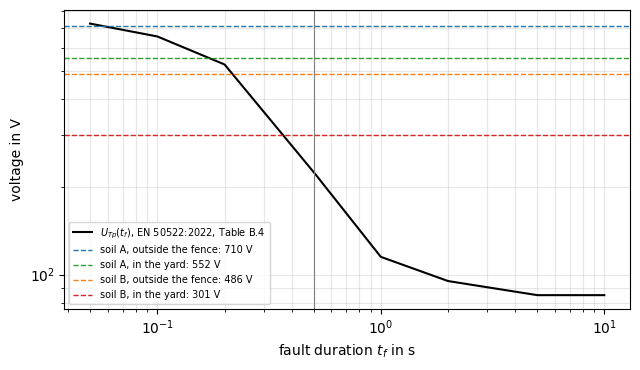

In [17]:
t = np.geomspace(0.05, 10.0, 600)
curve = np.array([gf.permissible_touch_voltage_en50522(v) for v in t])
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.loglog(t, curve, "k", label="$U_{Tp}(t_f)$, EN 50522:2022, Table B.4")
t_pass = {}
for (name, where), color in zip(
    [(n, w) for n in SOILS for w in ("outside", "yard")], ("C0", "C2", "C1", "C3")
):
    u = limits[name][where]
    t_pass[name, where] = t[curve >= u].max()
    label = "outside the fence" if where == "outside" else "in the yard"
    ax.axhline(u, color=color, lw=1.0, ls="--", label=f"soil {name}, {label}: {u:.0f} V")
    print(f"soil {name}, {label}: passes U_Tp only if t_f <= {t_pass[name, where]:.2f} s")
ax.axvline(T_F, color="grey", lw=0.8)
ax.set_xlabel("fault duration $t_f$ in s")
ax.set_ylabel("voltage in V")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=7)
fig.tight_layout()

Only a very fast protection would save the base design (0.06 s in
soil A, 0.22 s in soil B). So we change the earthing system, with two
measures of common practice:

1. a **grading conductor**: a closed conductor 1 m outside the grid and
   0.5 m deep, bonded to it, so that people outside the fence stand
   above a conductor;
2. in addition, **perimeter rods**: 20 rods of 6 m every 10 m along the
   outer conductor instead of the four corner rods; they reach 4.3 m into
   the lower layer.

The feet above the grading conductor are only 0.5 m from it, closer than
a 1 m segment is long, so the variants are solved with 0.5 m segments.
The base design at 0.5 m is already in the convergence study of
section 3.

In [18]:
VARIANTS = {
    "grading conductor": {"grading": True},
    "grading + perimeter rods": {"grading": True, "rods": "perimeter", "rod_length": 6.0},
}
fine = gf.create_engine(backend="mom", segment_length=0.5)
variants = {}
for name, soil in SOILS.items():
    base = convergence[name].set_index("segment_length_m").loc[0.5]
    variants[name, "base design"] = {q: base[q] for q in ("Z_E", "outside", "mesh", "yard")}
    for label, options in VARIANTS.items():
        world = substation(soil, **options)
        res = fine.solve(world)
        variants[name, label] = {"Z_E": res.input_impedance()[0].real, **touch(res, world)}

print("soil  variant                    Z_E in Ohm  U_E in V   yard   outside  bare U_Tp")
for (name, label), v in variants.items():
    verdict = "passes" if max(v["yard"], v["outside"]) <= u_tp else "fails"
    print(
        f"  {name}   {label:25s}   {v['Z_E']:.4f}    {v['Z_E'] * I_E:6.0f}   {v['yard']:5.0f}"
        f"    {v['outside']:5.0f}   {verdict}"
    )

soil  variant                    Z_E in Ohm  U_E in V   yard   outside  bare U_Tp
  A   base design                 0.7845      1569     555      711   fails
  A   grading conductor           0.7328      1466     455      308   fails
  A   grading + perimeter rods    0.5691      1138     262      188   fails
  B   base design                 1.7489      3498     300      486   fails
  B   grading conductor           1.6946      3389     121      186   passes
  B   grading + perimeter rods    1.6803      3361     115      178   passes


In [19]:
grading_b = variants["B", "grading conductor"]
assert max(grading_b["yard"], grading_b["outside"]) < u_tp  # soil B: grading is enough
both_a = variants["A", "grading + perimeter rods"]
assert both_a["outside"] < u_tp < both_a["yard"] < levels["A"]["shoes"] < levels["A"]["rock"]
assert both_a["Z_E"] < 0.85 * variants["A", "grading conductor"]["Z_E"]  # rods reach the bottom

What the variants show:

- **Soil B** needs only the grading conductor. It raises the surface
  potential where the people outside the fence stand and pulls the
  value there from 486 V to 186 V, the yard from 300 V to
  121 V: the design passes on bare contact. The perimeter rods add
  little in soil B, because their lower part stands in the 300 Ω·m
  bottom.
- **Soil A** is harder: the resistive top layer leaves a large share of
  $U_E$ between the grid and the surface everywhere. The grading
  conductor alone brings the fence to 308 V and leaves the yard at
  455 V. The perimeter rods reach the conductive bottom and lower
  $U_E$ itself, from 1466 V to 1138 V; the fence then passes on bare
  contact (188 V), but the corner meshes still have 262 V. With
  crushed rock in the yard ($U_{vTp}$ = 1125 V), or shoes on the natural
  soil ($U_{vTp}$ = 515 V), the design passes. Without either, smaller
  meshes near the corners would be the remaining measure: they lower the
  mesh voltage at the price of more conductor.

EN 50522 verifies a design by the calculated or measured touch voltages
of the installation as built. These numbers choose the measures; the
verification still follows.

## 8. Cross-checks: `image_2layer`, `mom_sommerfeld` and closed forms

The same two worlds, solved with the default engine (`image`, which
runs `image_2layer` for two-layer soil). Its touch voltages trigger the
`UniformCurrentFieldWarning`; we record it and print it once.

In [20]:
image = gf.create_engine(backend="image", segment_length=DS)
cross = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for name, world in worlds.items():
        res = image.solve(world)
        step = gf.step_voltage(res, position=corner, direction=(-1.0, -1.0, 0.0), world=world)
        cross[name] = {"Z_E": res.input_impedance()[0].real, **touch(res, world), "step": abs(step)}
        cross[name]["backend"] = res.metadata["effective_backend"]
caveat = [w for w in caught if issubclass(w.category, gf.UniformCurrentFieldWarning)]
print(f"{len(caveat)} warnings, the first:", str(caveat[0].message)[:230], "...")
print()
print("soil  backend        image_2layer / mom - 1:  Z_E     outside   mesh     yard     U_S corner")
for name in SOILS:
    ref = {"Z_E": z_e[name], **limits[name], "step": step_mom[name]}
    dev = {q: cross[name][q] / ref[q] - 1.0 for q in ref}
    cross[name]["dev"] = dev
    print(
        f"  {name}   {cross[name]['backend']}                        {dev['Z_E']:+6.1%}"
        f"   {dev['outside']:+6.1%}   {dev['mesh']:+6.1%}   {dev['yard']:+6.1%}   {dev['step']:+6.1%}"
    )

4 warnings, the first: step_voltage: uniform-current backend 'image_2layer' within 5 m of a grid, mesh, star, strip, open polyline or bonded multi-electrode cluster: the surface potential is impedance-grade (against 'mom': 20 m grid corner touch 1 m out ...

soil  backend        image_2layer / mom - 1:  Z_E     outside   mesh     yard     U_S corner
  A   image_2layer                         +1.6%    +2.1%    +7.1%    +7.1%    +4.5%
  B   image_2layer                         +0.6%   +12.5%   +45.4%   +25.7%    -4.7%


In [21]:
assert {c["backend"] for c in cross.values()} == {"image_2layer"}
assert all(abs(c["dev"]["Z_E"]) < 0.03 for c in cross.values())  # impedance-grade
assert cross["B"]["dev"]["mesh"] > 0.2  # the field near the grid is not
assert cross["B"]["dev"]["step"] < 0.0  # the unsafe side

For the **impedance** the two engines agree within 1.6 %: either
serves a study of $Z_E$ and $U_E$. For the **touch voltages** the
uniform current per wire of `image_2layer` overestimates, by up to
45 % at the mesh centres of soil B. Its step voltage at the corner
is 4.5 % high in soil A but 4.7 % low in soil B, on the unsafe side.
With a conductive top layer the current crowds strongly towards the ends
of every conductor, which one current per wire cannot follow. Assess
touch and step voltages near a grid with `mom`.

**`mom_sommerfeld`** evaluates the layered Green's function by numerical
Sommerfeld quadrature instead of the image series, on the same
discretisation as `mom`. Their agreement checks the series in this
strong contrast:

In [22]:
z_som = gf.create_engine(backend="mom_sommerfeld", segment_length=DS).solve(worlds["A"])
z_som = z_som.input_impedance()[0].real
print(
    f"soil A: mom {z_e['A']:.9f} Ohm, mom_sommerfeld {z_som:.9f} Ohm, "
    f"difference {abs(z_som / z_e['A'] - 1):.1e}"
)
assert abs(z_som / z_e["A"] - 1.0) < 1e-6

soil A: mom 0.783258102 Ohm, mom_sommerfeld 0.783258128 Ohm, difference 3.3e-08


**Closed forms.** The library offers Sverak's formula of IEEE Std 80 for
the grid resistance in homogeneous soil (section 4: +8.9 % above
`mom`) and Dwight's formulas for single electrodes (section 4: the
rods). It has no closed form for mesh or step voltages; IEEE Std 80's
$K_m$, $K_i$ and $K_s$ factors are not implemented. The homogeneous
limits of the next section are the strongest independent check of the
two-layer results.

## 9. Layer contrast and interface depth

First the interface depth: the two contrasts of soils A and B with
$h_1$ from 1.5 m to 50 m. The touch voltages are shown relative to
$U_E$, as the fraction of the earth potential rise that a person
bridges.

homogeneous soil: U_T / U_E = 0.262 (outside), 0.173 (yard)
300 over 50 Ω·m (K < 0): Z_E at h_1 = 50 m 2.2043 Ohm (rho_1 limit 2.6858 Ohm); U_T / U_E outside 0.314 ... 0.453
50 over 300 Ω·m (K > 0): Z_E at h_1 = 50 m 0.6401 Ohm (rho_1 limit 0.4476 Ohm); U_T / U_E outside 0.135 ... 0.187


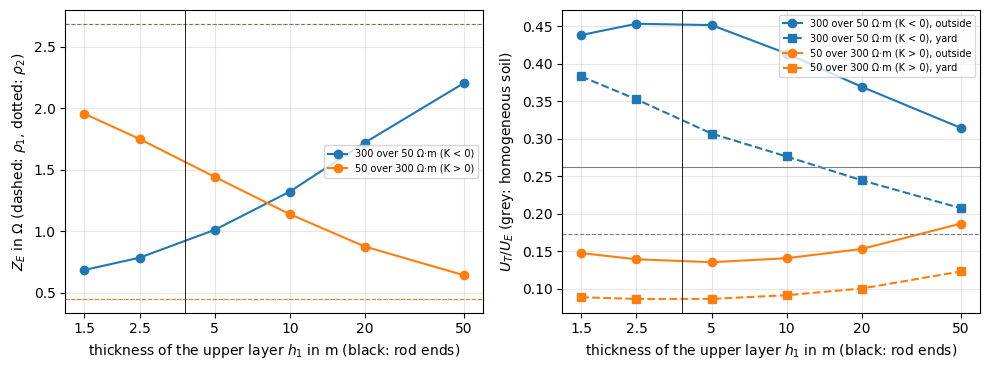

In [23]:
H_1 = [1.5, 2.5, 5.0, 10.0, 20.0, 50.0]
PAIRS = {"300 over 50 Ω·m (K < 0)": (300.0, 50.0), "50 over 300 Ω·m (K > 0)": (50.0, 300.0)}


def study(soil):
    """Z_E and the largest touch voltages outside and in the yard, as fractions of U_E."""
    world = substation(soil)
    res = mom.solve(world)
    z = res.input_impedance()[0].real
    t_v = touch(res, world)
    return z, t_v["outside"] / (z * I_E), t_v["yard"] / (z * I_E)


hom_touch = touch(homogeneous, hom_world)
hom_fraction = {q: v / (100.0 * z_1 * I_E) for q, v in hom_touch.items()}
depth_sweep = {
    label: np.array([study(gf.TwoLayerSoil(rho_1=r1, rho_2=r2, h_1=h)) for h in H_1])
    for label, (r1, r2) in PAIRS.items()
}

fig, (ax_z, ax_u) = plt.subplots(1, 2, figsize=(10.0, 3.8))
for k, (label, values) in enumerate(depth_sweep.items()):
    r1, r2 = PAIRS[label]
    ax_z.semilogx(H_1, values[:, 0], "o-", color=f"C{k}", label=label)
    ax_z.axhline(r1 * z_1, color=f"C{k}", ls="--", lw=0.8)
    ax_z.axhline(r2 * z_1, color=f"C{k}", ls=":", lw=0.8)
    ax_u.semilogx(H_1, values[:, 1], "o-", color=f"C{k}", label=f"{label}, outside")
    ax_u.semilogx(H_1, values[:, 2], "s--", color=f"C{k}", label=f"{label}, yard")
for q, ls in (("outside", "-"), ("yard", "--")):
    ax_u.axhline(hom_fraction[q], color="grey", ls=ls, lw=0.8)
ax_z.set_ylabel(r"$Z_E$ in Ω (dashed: $\rho_1$, dotted: $\rho_2$)")
ax_u.set_ylabel(r"$U_T / U_E$ (grey: homogeneous soil)")
for ax in (ax_z, ax_u):
    ax.axvline(DEPTH + ROD_LENGTH, color="k", lw=0.6)
    ax.set_xticks(H_1, [f"{h:g}" for h in H_1])
    ax.minorticks_off()
    ax.set_xlabel("thickness of the upper layer $h_1$ in m (black: rod ends)")
    ax.grid(True, alpha=0.3)
ax_z.legend(fontsize=7)
ax_u.legend(fontsize=7)
fig.tight_layout()
print(
    f"homogeneous soil: U_T / U_E = {hom_fraction['outside']:.3f} (outside), "
    f"{hom_fraction['yard']:.3f} (yard)"
)
for label, values in depth_sweep.items():
    r1, r2 = PAIRS[label]
    print(
        f"{label}: Z_E at h_1 = 50 m {values[-1, 0]:.4f} Ohm (rho_1 limit {r1 * z_1:.4f} Ohm); "
        f"U_T / U_E outside {values[:, 1].min():.3f} ... {values[:, 1].max():.3f}"
    )

In [24]:
for label, values in depth_sweep.items():
    r1, r2 = PAIRS[label]
    assert np.all(np.diff(values[:, 0]) > 0) if r1 > r2 else np.all(np.diff(values[:, 0]) < 0)
    low, high = sorted((r1 * z_1, r2 * z_1))
    assert np.all((values[:, 0] > low) & (values[:, 0] < high))
k_neg, k_pos = depth_sweep.values()
assert k_neg[:, 1].max() > 1.5 * hom_fraction["outside"] > hom_fraction["outside"] > k_pos[:, 1].min()

**The impedance** moves monotonically from the $\rho_2$ limit (thin
upper layer) towards the $\rho_1$ limit (thick upper layer), and
slowly: even at $h_1$ = 50 m it has not reached it, because the grid's
current field reaches deeper than its size.

**The touch-voltage fraction** behaves the other way round, and that is
the design lesson. With a resistive top over a conductive bottom
($K < 0$) a person outside the fence bridges up to 0.45 of $U_E$,
1.7 times the homogeneous value: the current leaves the grid
downwards, and the surface above it is pulled towards the low
potential of the conductive bottom. With a conductive top over a
resistive bottom ($K > 0$) the fraction drops below the homogeneous
value. A low $Z_E$ in soil A therefore does not mean low touch
voltages, and a high $Z_E$ in soil B does not mean high ones.

Now the contrast itself, with a 100 Ω·m upper layer of 2.5 m and the
lower layer from 10 to 1000 Ω·m:

rho_2 =     10 Ohm m, K = -0.82: Z_E = 0.2018 Ohm, U_T / U_E = 0.510 outside (0.420 in the yard), U_T =  206 V outside; homogeneous fraction x Z_E: 0.51 x U_T
rho_2 =     30 Ohm m, K = -0.54: Z_E = 0.3722 Ohm, U_T / U_E = 0.385 outside (0.274 in the yard), U_T =  287 V outside; homogeneous fraction x Z_E: 0.68 x U_T
rho_2 =    100 Ohm m, K = +0.00: Z_E = 0.8953 Ohm, U_T / U_E = 0.262 outside (0.173 in the yard), U_T =  469 V outside; homogeneous fraction x Z_E: 1.00 x U_T
rho_2 =    300 Ohm m, K = +0.50: Z_E = 2.1059 Ohm, U_T / U_E = 0.179 outside (0.113 in the yard), U_T =  752 V outside; homogeneous fraction x Z_E: 1.47 x U_T
rho_2 =   1000 Ohm m, K = +0.82: Z_E = 4.9246 Ohm, U_T / U_E = 0.115 outside (0.071 in the yard), U_T = 1137 V outside; homogeneous fraction x Z_E: 2.27 x U_T


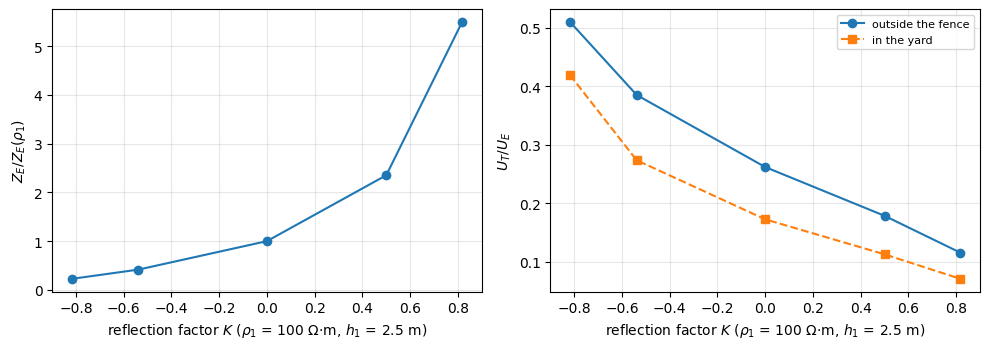

In [25]:
RHO_2 = [10.0, 30.0, 100.0, 300.0, 1000.0]
k_values = np.array([(r2 - 100.0) / (r2 + 100.0) for r2 in RHO_2])
contrast = np.array([study(gf.TwoLayerSoil(rho_1=100.0, rho_2=r2, h_1=2.5)) for r2 in RHO_2])

fig, (ax_z, ax_u) = plt.subplots(1, 2, figsize=(10.0, 3.6))
ax_z.plot(k_values, contrast[:, 0] / (100.0 * z_1), "o-")
ax_z.set_ylabel(r"$Z_E / Z_E(\rho_1)$")
ax_u.plot(k_values, contrast[:, 1], "o-", label="outside the fence")
ax_u.plot(k_values, contrast[:, 2], "s--", label="in the yard")
ax_u.set_ylabel(r"$U_T / U_E$")
ax_u.legend(fontsize=8)
for ax in (ax_z, ax_u):
    ax.set_xlabel(r"reflection factor $K$ ($\rho_1$ = 100 Ω·m, $h_1$ = 2.5 m)")
    ax.grid(alpha=0.3)
fig.tight_layout()
for r2, k, (z, outside, yard) in zip(RHO_2, k_values, contrast):
    print(
        f"rho_2 = {r2:6.0f} Ohm m, K = {k:+.2f}: Z_E = {z:.4f} Ohm, U_T / U_E = {outside:.3f} "
        f"outside ({yard:.3f} in the yard), U_T = {outside * z * I_E:4.0f} V outside; "
        f"homogeneous fraction x Z_E: {hom_fraction['outside'] / outside:.2f} x U_T"
    )

In [26]:
assert abs(contrast[2, 0] / (100.0 * z_1) - 1.0) < 1e-9  # K = 0 is homogeneous soil
assert np.all(np.diff(contrast[:, 0]) > 0) and np.all(np.diff(contrast[:, 1]) < 0)
print(f"runtime of this notebook: {time.perf_counter() - T_START:.0f} s")

runtime of this notebook: 73 s


Across the contrasts $Z_E$ grows by a factor of 24, while
the fraction $U_T/U_E$ outside the fence falls from 0.51 to
0.12. The touch voltage itself, $U_T = Z_E I_E \cdot
(U_T/U_E)$, grows by a factor of 5.5 only. Scaling the
homogeneous fraction with the two-layer impedance would understate the
touch voltage by half over the conductive bottom ($K$ = −0.82) and
overstate it 2.3 times over the resistive one ($K$ = +0.82): wrong
in both directions, and on the unsafe side where the bottom conducts.

## 10. What this means for the design

- **Measure deep.** A 60 m × 40 m grid sees the soil to tens of metres:
  its apparent resistivity is 88 Ω·m in soil A and 195 Ω·m in
  soil B. The sounding must reach depths of the order of the grid size.
- **The earth potential rise is not the hazard.** Soil B has more than
  twice the $U_E$ of soil A but lower touch voltages (486 V against 710 V
  outside the fence, 301 V against 552 V in the yard). Calculate the
  touch voltages (EN 50522 criterion C4) with a field-grade engine.
- **Use `mom` for touch and step voltages near a grid.** `image_2layer`
  is fine for $Z_E$ (within 1.6 % here) but overestimates the mesh
  voltages by up to 45 % and, in soil B, underestimates the step
  voltage at a corner.
- **Check the corners.** The largest touch voltages stand 1 m outside a
  corner and, in soil B, right above the corner conductor. Sample them:
  360 rays, touch points at the corner posts, or a dense map.
- **The measures depend on the soil.** In soil B a grading conductor
  outside the fence is enough. In soil A rods into the conductive
  bottom, the grading conductor and a surface layer in the yard (or
  smaller corner meshes) are needed.

## Limits of this example

- **Equipotential grid, no inductive effects.** The copper's resistance
  and inductance are neglected, and so is the inductive coupling to the
  faulted line. For grids of several hundred metres, steel conductors or
  frequencies well above 50 Hz the potential varies along the grid, and
  this model does not show it.
- **The earth-fault current is given.** The split of the fault current
  between the grid, the earth wires and the cable screens (the reduction
  factors) is not computed; tutorial
  [T06](../tutorials/T06_tn_network_synthetic_and_osm.ipynb) shows how a
  connected network shares the current. Transferred potentials (cable
  screens, pipes, a fence that leaves the site) are not assessed.
- **The soil is two horizontal layers** from an assumed sounding,
  without seasonal variation or frozen ground. Three or more layers need
  `mom_sommerfeld`, and `FieldResult.potential` raises
  `NotImplementedError` for them, so touch voltages in three-layer soil
  are out of reach.
- **Crushed rock enters only as a resistance under the feet** ($R_{F2}$
  of EN 50522). Its thin high-resistivity layer would be a third soil
  layer, which the field model does not include.
- **Point kernel of `mom`.** Its impedance changes by about 0.2 % from 1
  m to 0.25 m segments here and stays slightly below the exact value;
  the surface potential directly above a shallow conductor needs
  segments shorter than the conductor's depth (section 7).
- **EN 50522 in the library:** the permissible touch voltage of Table
  B.4 (80 V beyond 10 s) and the prospective value of Annex B.4. The
  permissible step voltage (Annex A.3), the measures M (Annex E) and the
  global earthing system (criterion C1) are not implemented; IEEE Std 80
  enters only through Sverak's resistance formula.
- **No `fem` reference.** The 3-D model of `fem` is the independent
  reference for small clusters; a grid with 1 km of wire is far beyond
  its default node limit. The cross-checks here are `image_2layer`,
  `mom_sommerfeld`, the homogeneous limits and the closed forms.

See also the how-to [assess touch voltages](../how-to/assess-touch-voltages.md)
and the [known limitations](../reference/known-limitations.md).